# 1. Preparación de Datos y Modelo
Cargamos el dataset CIFAR-10 y el modelo ResNet-20 pre-entrenado.

In [7]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn

# ==========================================
# 1. PREPARACIÓN DE DATOS Y MODELO
# ==========================================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2023, 0.1994, 0.201])
])

print("Descargando/Cargando datasets...")
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
# Usamos el testloader para la evaluación del ataque
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

print("Cargando el modelo cifar10_resnet20...")
model = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar10_resnet20", pretrained=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("-" * 30)
print(f"✅ Dispositivo configurado: {device}")
print(f"✅ Tamaño del dataset de test: {len(testset)} imágenes")
print("-" * 30)

Descargando/Cargando datasets...
Files already downloaded and verified


c:\Users\LENOVO\Desktop\Workspace\Slesi\.venv\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Cargando el modelo cifar10_resnet20...
------------------------------
✅ Dispositivo configurado: cuda
✅ Tamaño del dataset de test: 10000 imágenes
------------------------------


Using cache found in C:\Users\LENOVO/.cache\torch\hub\chenyaofo_pytorch-cifar-models_master


# 2. Implementación Manual de FGSM
Implementación del ataque Fast Gradient Sign Method (Norma $L_\infty$).

In [8]:
def fgsm_attack(images, epsilon, data_grad):
    # 1. Obtener el signo de los gradientes
    sign_data_grad = data_grad.sign()
    
    # 2. Crear la imagen adversaria añadiendo la perturbación
    perturbed_images = images + epsilon * sign_data_grad
    
    # Nota: Debido a la normalización estricta de CIFAR-10, omitimos el "clipping" a [0,1] 
    # en el espacio normalizado, ya que alteraría los rangos estandarizados reales.
    return perturbed_images

def evaluate_evasion_attack(model, testloader, epsilon, min_images=1000):
    print(f"Iniciando evaluación de FGSM (epsilon = {epsilon})...")
    
    # El modelo debe estar en modo evaluación
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    correct_clean = 0
    correct_adv = 0
    total = 0
    
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        
        # --- A. PRECISION ORIGINAL (Limpia) ---
        # No necesitamos gradientes para evaluar las imágenes originales
        with torch.no_grad():
            outputs_clean = model(images)
            _, predicted_clean = torch.max(outputs_clean.data, 1)
            correct_clean += (predicted_clean == labels).sum().item()
            
        # --- B. ATAQUE ADVERSARIO ---
        # Habilitamos el cálculo de gradientes para las imágenes de entrada
        images.requires_grad = True
        
        # Forward pass para obtener gradientes
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Limpiar gradientes previos del modelo
        model.zero_grad()
        
        # Backward pass para calcular los gradientes de la imagen
        loss.backward()
        
        # Extraer los gradientes de las imágenes
        data_grad = images.grad.data
        
        # Generar las imágenes adversarias
        perturbed_images = fgsm_attack(images, epsilon, data_grad)
        
        # --- C. PRECISION ADVERSARIA ---
        # Evaluamos el modelo de nuevo usando las imágenes manipuladas
        with torch.no_grad():
            outputs_adv = model(perturbed_images)
            _, predicted_adv = torch.max(outputs_adv.data, 1)
            correct_adv += (predicted_adv == labels).sum().item()
            
        total += labels.size(0)
        
        # Detener la evaluación si ya superamos el mínimo requerido (1000)
        if total >= min_images:
            break
        # Calcular métricas finales
    clean_acc = 100 * correct_clean / total
    adv_acc = 100 * correct_adv / total
    
    print("=" * 30)
    print(f"📊 Resultados sobre {total} imágenes:")
    print(f"Precisión Limpia (Sin ataque): {clean_acc:.2f}%")
    print(f"Precisión Adversa (Con FGSM):  {adv_acc:.2f}%")
    print(f"Caída de precisión:            {clean_acc - adv_acc:.2f}%")
    print("=" * 30)

epsilon_value = 0.05
evaluate_evasion_attack(model, testloader, epsilon=epsilon_value, min_images=1000)

Iniciando evaluación de FGSM (epsilon = 0.05)...
📊 Resultados sobre 1024 imágenes:
Precisión Limpia (Sin ataque): 92.68%
Precisión Adversa (Con FGSM):  21.48%
Caída de precisión:            71.19%


# 3. Ataque Iterativo PGD (ART Framework)
Uso de la librería ART para realizar Projected Gradient Descent.

In [9]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import ProjectedGradientDescent

# Asumiendo que ya tienes 'model', 'testloader' y 'device' del código anterior

def evaluate_pgd_with_art(model, testloader, epsilon, min_images=1000):
    print(f"Configurando PGD mediante ART (epsilon = {epsilon})...")
    
    # 1. Preparar el modelo para ART
    model.eval()
    criterion = nn.CrossEntropyLoss()
    # ART requiere un optimizador en su constructor por diseño de su API, 
    # aunque para ataques de evasión en inferencia no se usa para entrenar.
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    
    # Envolvemos el modelo de PyTorch en el clasificador de ART
    classifier = PyTorchClassifier(
        model=model,
        loss=criterion,
        optimizer=optimizer,
        input_shape=(3, 32, 32), # Dimensión de las imágenes CIFAR-10
        nb_classes=10,
        device_type='gpu' if torch.cuda.is_available() else 'cpu'
    )
    
    # 2. Configurar el ataque PGD
    # eps: Magnitud máxima de la perturbación (igual que en FGSM)
    # eps_step: Tamaño del paso en cada iteración (suele ser eps / (iteraciones/2) o similar)
    # max_iter: Número de iteraciones del ataque
    attack_pgd = ProjectedGradientDescent(
        estimator=classifier,
        eps=epsilon,
        eps_step=epsilon/4, 
        max_iter=10,
        batch_size=64,
        targeted=False
    )
    
    # 3. Bucle de evaluación
    correct_clean = 0
    correct_adv = 0
    total = 0
    
    print("Generando ejemplos adversarios y evaluando...")
    
    for images, labels in testloader:
        # ART trabaja nativamente con arrays de NumPy, así que convertimos los tensores
        images_np = images.cpu().numpy()
        labels_np = labels.cpu().numpy()
        
        # --- A. PRECISIÓN ORIGINAL ---
        # Predicciones limpias usando la API de ART
        preds_clean = classifier.predict(images_np)
        correct_clean += np.sum(np.argmax(preds_clean, axis=1) == labels_np)
        
        # --- B. GENERACIÓN DEL ATAQUE ---
        # ART se encarga de todo el proceso iterativo interno
        images_adv_np = attack_pgd.generate(x=images_np)
        
        # --- C. PRECISIÓN ADVERSARIA ---
        preds_adv = classifier.predict(images_adv_np)
        correct_adv += np.sum(np.argmax(preds_adv, axis=1) == labels_np)
        
        total += len(labels_np)
        
        # Imprimir progreso para saber que no se ha quedado colgado
        print(f"Procesadas {total} imágenes...", end='\r')
        
        if total >= min_images:
            break

    # 4. Resultados
    clean_acc = 100 * correct_clean / total
    adv_acc = 100 * correct_adv / total
    
    print("\n" + "=" * 40)
    print(f"📊 Resultados PGD (ART) sobre {total} imágenes:")
    print(f"Iteraciones (max_iter):        10")
    print(f"Tamaño de paso (eps_step):     {epsilon/4:.4f}")
    print(f"Precisión Limpia (Sin ataque): {clean_acc:.2f}%")
    print(f"Precisión Adversa (Con PGD):   {adv_acc:.2f}%")
    print(f"Caída de precisión:            {clean_acc - adv_acc:.2f}%")
    print("=" * 40)

# Ejecutar la evaluación (mantenemos el epsilon de 0.05 para poder comparar con FGSM)
evaluate_pgd_with_art(model, testloader, epsilon=0.05, min_images=1000)

Configurando PGD mediante ART (epsilon = 0.05)...
Generando ejemplos adversarios y evaluando...


PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

...

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Procesadas 1024 imágenes...
📊 Resultados PGD (ART) sobre 1024 imágenes:
Iteraciones (max_iter):        10
Tamaño de paso (eps_step):     0.0125
Precisión Limpia (Sin ataque): 92.68%
Precisión Adversa (Con PGD):   5.57%
Caída de precisión:            87.11%


# 4. Gráfica Comparativa: ASR vs Epsilon
Evaluación de la tasa de éxito de ambos ataques frente a diferentes presupuestos de ruido.


Iniciando evaluación comparativa (ASR vs Epsilon)...

➡️ Evaluando Epsilon: 0.0

➡️ Evaluando Epsilon: 0.01


<>:130: SyntaxWarning: invalid escape sequence '\e'
<>:131: SyntaxWarning: invalid escape sequence '\e'
<>:130: SyntaxWarning: invalid escape sequence '\e'
<>:131: SyntaxWarning: invalid escape sequence '\e'
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11220\2641255491.py:130: SyntaxWarning: invalid escape sequence '\e'
  plt.title('Tasa de Éxito (ASR) vs Presupuesto de Perturbación ($\epsilon$)', fontsize=14, fontweight='bold', pad=15)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11220\2641255491.py:131: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('Presupuesto de Perturbación ($\epsilon$) en norma $L_\infty$', fontsize=12)


PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

...

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/1 [00:00<?, ?it/s]

   ASR FGSM: 86.62% | ASR PGD: 100.00%


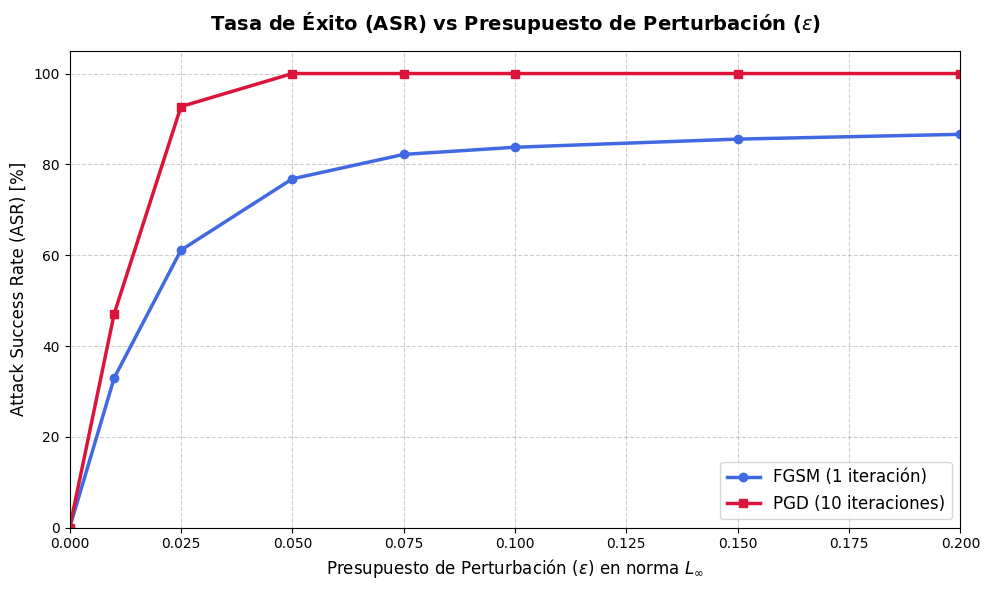

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from art.attacks.evasion import ProjectedGradientDescent
from art.estimators.classification import PyTorchClassifier

# Asumimos que 'model', 'testloader', 'device' y 'fgsm_attack' ya están en memoria

def generate_asr_curve(model, testloader, epsilons, min_images=1000):
    print("\n" + "="*50)
    print("Iniciando evaluación comparativa (ASR vs Epsilon)...")
    print("="*50)
    
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    # 1. Configurar el clasificador base de ART (fuera del bucle para no repetir)
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    classifier = PyTorchClassifier(
        model=model,
        loss=criterion,
        optimizer=optimizer,
        input_shape=(3, 32, 32),
        nb_classes=10,
        device_type='gpu' if torch.cuda.is_available() else 'cpu'
    )
    
    asr_fgsm_list = []
    asr_pgd_list = []
    
    # 2. Bucle principal sobre los presupuestos de perturbación
    for eps in epsilons:
        print(f"\n➡️ Evaluando Epsilon: {eps}")
        
        # Si eps es 0, no hay ataque, el ASR es 0% por definición
        if eps == 0.0:
            asr_fgsm_list.append(0.0)
            asr_pgd_list.append(0.0)
            continue
            
        # Instanciar PGD para el epsilon actual (10 iteraciones es estándar)
        attack_pgd = ProjectedGradientDescent(
            estimator=classifier, eps=eps, eps_step=eps/4, max_iter=10, batch_size=64, targeted=False
        )
        
        successful_fgsm = 0
        successful_pgd = 0
        total_correct_clean = 0
        processed = 0
        
        # 3. Bucle de evaluación sobre el dataset
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            
            # --- A. Predicciones Limpias (Baseline) ---
            images.requires_grad = True
            outputs_clean = model(images)
            _, preds_clean = torch.max(outputs_clean, 1)
            
            # Máscara lógica de imágenes correctamente clasificadas
            correct_mask = (preds_clean == labels)
            total_correct_clean += correct_mask.sum().item()
            
            # --- B. Ataque FGSM ---
            loss = criterion(outputs_clean, labels)
            model.zero_grad()
            loss.backward()
            data_grad = images.grad.data
            
            # Generar y evaluar
            images_fgsm = fgsm_attack(images, eps, data_grad)
            with torch.no_grad():
                outputs_fgsm = model(images_fgsm)
                _, preds_fgsm = torch.max(outputs_fgsm, 1)
            
            # Contar éxito: modelo se equivoca AHORA, pero acertó ANTES
            successful_fgsm += ((preds_fgsm != labels) & correct_mask).sum().item()
            
            # --- C. Ataque PGD (ART) ---
            # Pasar a NumPy para ART
            images_np = images.detach().cpu().numpy()
            labels_np = labels.cpu().numpy()
            correct_mask_np = correct_mask.cpu().numpy()
            
            # Generar y evaluar
            images_pgd_np = attack_pgd.generate(x=images_np)
            preds_pgd_np = np.argmax(classifier.predict(images_pgd_np), axis=1)
            
            # Contar éxito PGD
            successful_pgd += np.sum((preds_pgd_np != labels_np) & correct_mask_np)
            
            processed += labels.size(0)
            if processed >= min_images:
                break
                
        # --- D. Cálculo del ASR Final para este Epsilon ---
        # ASR = (Ataques Exitosos / Total Imágenes Originalmente Correctas) * 100
        asr_fgsm = (successful_fgsm / total_correct_clean) * 100.0 if total_correct_clean > 0 else 0
        asr_pgd = (successful_pgd / total_correct_clean) * 100.0 if total_correct_clean > 0 else 0
        
        asr_fgsm_list.append(asr_fgsm)
        asr_pgd_list.append(asr_pgd)
        
        print(f"   ASR FGSM: {asr_fgsm:.2f}% | ASR PGD: {asr_pgd:.2f}%")
        
    return epsilons, asr_fgsm_list, asr_pgd_list

# ==========================================
# EJECUCIÓN Y GENERACIÓN DE LA GRÁFICA
# ==========================================
# Definimos el rango de presupuestos L_infinito a evaluar
epsilons_to_test = [0.0, 0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2]

# Obtener los datos (esto puede tardar unos minutos debido a las iteraciones de PGD)
eps_vals, asr_fgsm_vals, asr_pgd_vals = generate_asr_curve(
    model, testloader, epsilons_to_test, min_images=1000
)

# Configuración visual con Matplotlib
plt.figure(figsize=(10, 6))

# Plotear ambas curvas
plt.plot(eps_vals, asr_fgsm_vals, marker='o', linewidth=2.5, color='royalblue', label='FGSM (1 iteración)')
plt.plot(eps_vals, asr_pgd_vals, marker='s', linewidth=2.5, color='crimson', label='PGD (10 iteraciones)')

# Detalles estéticos de la gráfica
plt.grid(True, linestyle='--', alpha=0.6)
plt.title('Tasa de Éxito (ASR) vs Presupuesto de Perturbación ($\epsilon$)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Presupuesto de Perturbación ($\epsilon$) en norma $L_\infty$', fontsize=12)
plt.ylabel('Attack Success Rate (ASR) [%]', fontsize=12)
plt.legend(fontsize=12, loc='lower right')

# Ajustar límites de los ejes
plt.xlim(0, max(eps_vals))
plt.ylim(0, 105)

plt.tight_layout()
# Descomenta la siguiente línea si quieres guardar la imagen en tu disco duro
# plt.savefig('grafica_asr_comparativa.png', dpi=300)
plt.show()

# ==========================================
# 2. DEFENSA EN INFERENCIA: COMPRESIÓN JPEG
# ==========================================
A continuación, implementamos una defensa basada en **preprocesamiento** para mitigar el efecto de los ataques de evasión.
La compresión JPEG reduce la redundancia de alta frecuencia en las imágenes, donde a menudo se esconde el ruido adversario.

In [11]:
import io
from PIL import Image
import torch
import torchvision.transforms as transforms
import torch.nn as nn
import numpy as np
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import ProjectedGradientDescent

def jpeg_compression_defense(images_tensor, quality=75):
    device = images_tensor.device
    # CIFAR-10 stats
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.2023, 0.1994, 0.201]).view(1, 3, 1, 1).to(device)
    
    # Denormalize to [0,1]
    images = images_tensor * std + mean
    images = torch.clamp(images, 0, 1)
    
    compressed_list = []
    to_pil = transforms.ToPILImage()
    to_tensor = transforms.ToTensor()
    
    for i in range(images.size(0)):
        img_pil = to_pil(images[i].detach().cpu())
        buffer = io.BytesIO()
        img_pil.save(buffer, format='JPEG', quality=quality)
        buffer.seek(0)
        img_jpg = Image.open(buffer)
        compressed_list.append(to_tensor(img_jpg))
        
    images_defended = torch.stack(compressed_list).to(device)
    # Re-normalize
    images_defended = (images_defended - mean) / std
    return images_defended

def evaluate_defense(model, testloader, epsilon, quality=50, min_images=1000):
    print(f"--- Evaluación de Defensa (JPEG Calidad={quality}, Epsilon={epsilon}) ---")
    model.eval()
    criterion = nn.CrossEntropyLoss()
    
    # Configurar ART para PGD dentro de la defensa
    classifier = PyTorchClassifier(
        model=model, loss=criterion, nb_classes=10, 
        input_shape=(3, 32, 32), device_type='gpu' if torch.cuda.is_available() else 'cpu'
    )
    attack_pgd = ProjectedGradientDescent(estimator=classifier, eps=epsilon, eps_step=epsilon/4, max_iter=10, targeted=False)
    
    # Contadores
    total = 0
    correct_clean = 0
    correct_defended = 0
    
    success_fgsm = 0
    success_fgsm_defended = 0
    
    success_pgd = 0
    success_pgd_defended = 0

    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        
        # 1. Limpio
        with torch.no_grad():
            preds_clean = torch.argmax(model(images), 1)
            mask_correct = (preds_clean == labels)
            correct_clean += mask_correct.sum().item()
            
            # Limpio con defensa
            images_clean_def = jpeg_compression_defense(images, quality)
            preds_clean_def = torch.argmax(model(images_clean_def), 1)
            correct_defended += (preds_clean_def == labels).sum().item()
        
        # Solo evaluamos ASR sobre las que el modelo acierta inicialmente
        idx_correct = torch.where(mask_correct)[0]
        if len(idx_correct) == 0: continue
        
        images_sub = images[idx_correct]
        labels_sub = labels[idx_correct]
        
        # 2. FGSM
        images_sub.requires_grad = True
        outputs = model(images_sub)
        loss = criterion(outputs, labels_sub)
        model.zero_grad()
        loss.backward()
        adv_fgsm = fgsm_attack(images_sub, epsilon, images_sub.grad.data)
        
        # 3. PGD (ART)
        adv_pgd_np = attack_pgd.generate(x=images_sub.detach().cpu().numpy())
        adv_pgd = torch.from_numpy(adv_pgd_np).to(device)

        with torch.no_grad():
            # Evaluar FGSM
            p_fgsm = torch.argmax(model(adv_fgsm), 1)
            success_fgsm += (p_fgsm != labels_sub).sum().item()
            
            p_fgsm_def = torch.argmax(model(jpeg_compression_defense(adv_fgsm, quality)), 1)
            success_fgsm_defended += (p_fgsm_def != labels_sub).sum().item()
            
            # Evaluar PGD
            p_pgd = torch.argmax(model(adv_pgd), 1)
            success_pgd += (p_pgd != labels_sub).sum().item()
            
            p_pgd_def = torch.argmax(model(jpeg_compression_defense(adv_pgd, quality)), 1)
            success_pgd_defended += (p_pgd_def != labels_sub).sum().item()

        total += images.size(0)
        if total >= min_images: break

    # Métricas
    cda_orig = 100 * correct_clean / total
    cda_def  = 100 * correct_defended / total
    
    asr_fgsm_orig = 100 * success_fgsm / correct_clean
    asr_fgsm_def  = 100 * success_fgsm_defended / correct_clean
    
    asr_pgd_orig = 100 * success_pgd / correct_clean
    asr_pgd_def  = 100 * success_pgd_defended / correct_clean

    print(f"📊 Utilidad (CDA): {cda_orig:.2f}% -> {cda_def:.2f}% (Caída: {cda_orig - cda_def:.2f}%)")
    print(f"🔥 ASR FGSM:      {asr_fgsm_orig:.2f}% -> {asr_fgsm_def:.2f}% (Mitigación: {asr_fgsm_orig - asr_fgsm_def:.2f}%)")
    print(f"🔥 ASR PGD:       {asr_pgd_orig:.2f}% -> {asr_pgd_def:.2f}% (Mitigación: {asr_pgd_orig - asr_pgd_def:.2f}%)")

evaluate_defense(model, testloader, epsilon=0.05, quality=50)

--- Evaluación de Defensa (JPEG Calidad=50, Epsilon=0.05) ---


PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

...

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

PGD - Batches:   0%|          | 0/2 [00:00<?, ?it/s]

📊 Utilidad (CDA): 92.68% -> 72.85% (Caída: 19.82%)
🔥 ASR FGSM:      76.82% -> 30.66% (Mitigación: 46.15%)
🔥 ASR PGD:       100.00% -> 31.19% (Mitigación: 68.81%)


# ==========================================
# 3. EVIDENCIAS VISUALES
# ==========================================
Visualizamos el ruido generado y el efecto de la perturbación en una imagen del dataset.

<>:52: SyntaxWarning: invalid escape sequence '\e'
<>:52: SyntaxWarning: invalid escape sequence '\e'
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11220\874925466.py:52: SyntaxWarning: invalid escape sequence '\e'
  plt.title(f"Ruido Amplificado (10x)\n($\epsilon={epsilon}$)")


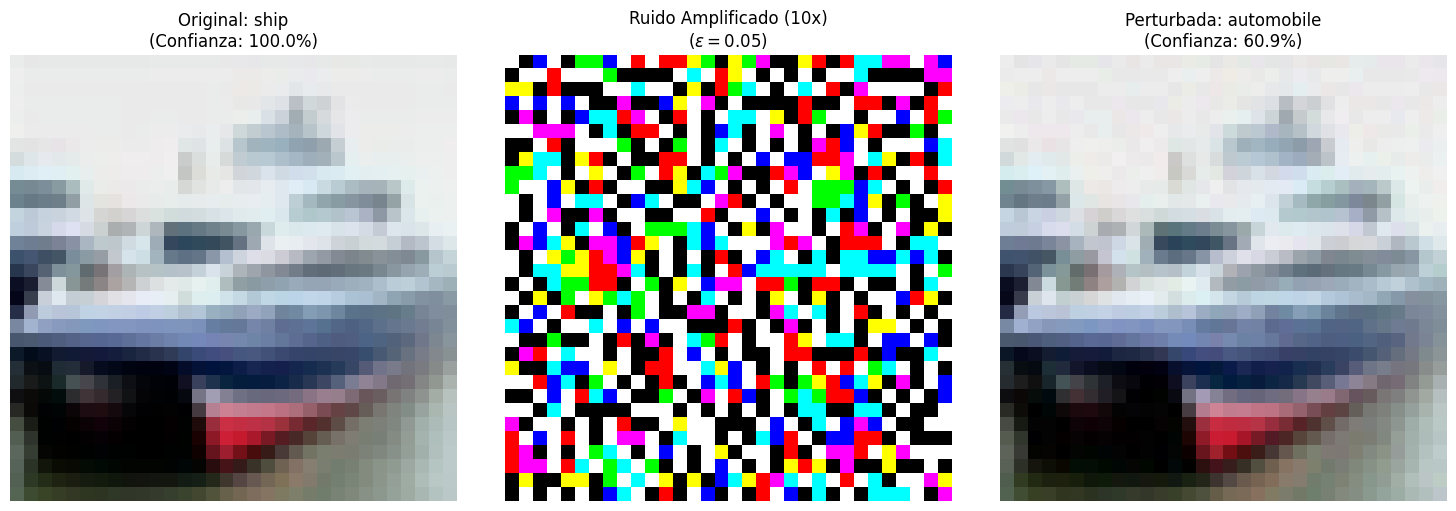

In [12]:
def show_adversarial_evidence(model, test_loader, epsilon):
    model.eval()
    classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
    inv_normalize = transforms.Normalize(
        mean=[-0.4914/0.2023, -0.4822/0.1994, -0.4465/0.201], 
        std=[1/0.2023, 1/0.1994, 1/0.201]
    )

    found = False
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        images.requires_grad = True
        
        outputs = model(images)
        preds = torch.argmax(outputs, 1)
        
        # Buscar una imagen donde el modelo acierte y el ataque FGSM funcione
        loss = nn.CrossEntropyLoss()(outputs, labels)
        model.zero_grad()
        loss.backward()
        adv_images = fgsm_attack(images, epsilon, images.grad.data)
        
        preds_adv = torch.argmax(model(adv_images), 1)
        
        for i in range(len(labels)):
            if preds[i] == labels[i] and preds_adv[i] != labels[i]:
                # Éxito encontrado
                idx = i
                found = True
                break
        if found: break

    if not found:
        print("No se encontró un ataque exitoso en el primer batch. Probando con batch 0.")
        idx = 0
    
    orig_img = inv_normalize(images[idx]).detach().cpu().numpy().transpose(1, 2, 0)
    adv_img = inv_normalize(adv_images[idx]).detach().cpu().numpy().transpose(1, 2, 0)
    noise_img = (adv_images[idx] - images[idx]).detach().cpu().numpy().transpose(1, 2, 0)
    
    # Amplificar el ruido para que sea visible (escalado a [0,1])
    noise_visible = np.clip((noise_img / epsilon + 0.5), 0, 1)

    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.title(f"Original: {classes[labels[idx]]}\n(Confianza: {torch.softmax(outputs[idx], 0)[labels[idx]]*100:.1f}%)")
    plt.imshow(np.clip(orig_img, 0, 1))
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title(f"Ruido Amplificado (10x)\n($\epsilon={epsilon}$)")
    plt.imshow(noise_visible)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    outputs_adv = model(adv_images[idx].unsqueeze(0))
    conf_adv = torch.softmax(outputs_adv[0], 0)[preds_adv[idx]]*100
    plt.title(f"Perturbada: {classes[preds_adv[idx]]}\n(Confianza: {conf_adv:.1f}%)")
    plt.imshow(np.clip(adv_img, 0, 1))
    plt.axis('off')

    plt.tight_layout()
    plt.show()

show_adversarial_evidence(model, testloader, epsilon=0.05)